In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

In [3]:
df_transactions = pd.read_csv(r"D:\Expense_tracker_project\datasets\transactions.csv")
df_transactions.head()

,Transaction ID,Date,Description,Category,Subcategory,Amount (TND),Type,Payment Method,Is Recurring,Notes
0,TXN0001,2024-01-01,Virement Salaire Net,Income,Salary,3200.000,Income,Bank Transfer,Yes,NaN
1,TXN0002,2024-01-01,Pharmacie Cosmétiques,Personal Care,Cosmetics,-8.852,Expense,Credit Card,No,NaN
2,TXN0003,2024-01-01,Institut Beauté,Personal Care,Beauty Treatment,-7.478,Expense,Debit Card,No,NaN
3,TXN0004,2024-01-02,Loyer Appartement Lac II,Rent,Apartment Rent,-750.000,Expense,Bank Transfer,Yes,Fixed monthly rent
4,TXN0005,2024-01-02,Monoprix Lac,Food & Groceries,Supermarket,-73.341,Expense,Credit Card,No,NaN


In [4]:
df_budget = pd.read_csv(r"D:\Expense_tracker_project\datasets\budget.csv")
df_budget.head()

,Category,January 2024,February 2024,March 2024,April 2024,May 2024,June 2024,July 2024,August 2024,September 2024,October 2024,November 2024,December 2024
0,Food & Groceries,450,450,450,500,400,450,500,450,400,400,450,500
1,Transport,180,150,180,150,200,150,150,180,150,180,160,150
2,Restaurants & Cafés,150,130,130,120,200,150,180,150,150,150,160,100
3,Health & Wellness,200,200,180,250,200,150,180,250,150,150,200,150
4,Education & Self-Dev,200,150,100,200,200,200,100,150,300,200,250,200


In [5]:
df_transactions["Amount_INR"] = df_transactions["Amount (TND)"] * 29

In [6]:
df_transactions.drop("Amount (TND)", axis=1, inplace=True)
df_transactions.rename(
    columns={"Amount_INR": "Amount"},
    inplace=True
)

In [7]:
df_transactions.head()

,Transaction ID,Date,Description,Category,Subcategory,Type,Payment Method,Is Recurring,Notes,Amount
0,TXN0001,2024-01-01,Virement Salaire Net,Income,Salary,Income,Bank Transfer,Yes,NaN,92800.000
1,TXN0002,2024-01-01,Pharmacie Cosmétiques,Personal Care,Cosmetics,Expense,Credit Card,No,NaN,-256.708
2,TXN0003,2024-01-01,Institut Beauté,Personal Care,Beauty Treatment,Expense,Debit Card,No,NaN,-216.862
3,TXN0004,2024-01-02,Loyer Appartement Lac II,Rent,Apartment Rent,Expense,Bank Transfer,Yes,Fixed monthly rent,-21750.000
4,TXN0005,2024-01-02,Monoprix Lac,Food & Groceries,Supermarket,Expense,Credit Card,No,NaN,-2126.889


**Creating the Expenses dataset**

In [8]:
df_expenses = df_transactions[
    df_transactions["Type"] == "Expense"
]

df_expenses.head()

,Transaction ID,Date,Description,Category,Subcategory,Type,Payment Method,Is Recurring,Notes,Amount
1,TXN0002,2024-01-01,Pharmacie Cosmétiques,Personal Care,Cosmetics,Expense,Credit Card,No,NaN,-256.708
2,TXN0003,2024-01-01,Institut Beauté,Personal Care,Beauty Treatment,Expense,Debit Card,No,NaN,-216.862
3,TXN0004,2024-01-02,Loyer Appartement Lac II,Rent,Apartment Rent,Expense,Bank Transfer,Yes,Fixed monthly rent,-21750.000
4,TXN0005,2024-01-02,Monoprix Lac,Food & Groceries,Supermarket,Expense,Credit Card,No,NaN,-2126.889
5,TXN0006,2024-01-02,Hôtel Hasdrubal Djerba,Travel & Holidays,Hotel,Expense,Credit Card,No,NaN,-659.170


In [9]:
df_expenses.shape

(769, 10)

In [10]:
df_expenses["Amount"] = (
    df_expenses["Amount"].abs()
)

In [11]:
df_expenses.head()

,Transaction ID,Date,Description,Category,Subcategory,Type,Payment Method,Is Recurring,Notes,Amount
1,TXN0002,2024-01-01,Pharmacie Cosmétiques,Personal Care,Cosmetics,Expense,Credit Card,No,NaN,256.708
2,TXN0003,2024-01-01,Institut Beauté,Personal Care,Beauty Treatment,Expense,Debit Card,No,NaN,216.862
3,TXN0004,2024-01-02,Loyer Appartement Lac II,Rent,Apartment Rent,Expense,Bank Transfer,Yes,Fixed monthly rent,21750.000
4,TXN0005,2024-01-02,Monoprix Lac,Food & Groceries,Supermarket,Expense,Credit Card,No,NaN,2126.889
5,TXN0006,2024-01-02,Hôtel Hasdrubal Djerba,Travel & Holidays,Hotel,Expense,Credit Card,No,NaN,659.170


In [12]:
df_expenses.isnull().sum()

Transaction ID      0
Date                0
Description         0
Category            0
Subcategory         0
Type                0
Payment Method      0
Is Recurring        0
Notes             677
Amount              0
dtype: int64

In [13]:
df_expenses["Date"] = pd.to_datetime(
    df_expenses["Date"]
)

In [14]:
df_expenses["Month"] = (
    df_expenses["Date"].dt.month
)

df_expenses["Year"] = (
    df_expenses["Date"].dt.year
)

In [15]:
df_expenses.head()

,Transaction ID,Date,Description,Category,Subcategory,Type,Payment Method,Is Recurring,Notes,Amount,Month,Year
1,TXN0002,2024-01-01,Pharmacie Cosmétiques,Personal Care,Cosmetics,Expense,Credit Card,No,NaN,256.708,1,2024
2,TXN0003,2024-01-01,Institut Beauté,Personal Care,Beauty Treatment,Expense,Debit Card,No,NaN,216.862,1,2024
3,TXN0004,2024-01-02,Loyer Appartement Lac II,Rent,Apartment Rent,Expense,Bank Transfer,Yes,Fixed monthly rent,21750.000,1,2024
4,TXN0005,2024-01-02,Monoprix Lac,Food & Groceries,Supermarket,Expense,Credit Card,No,NaN,2126.889,1,2024
5,TXN0006,2024-01-02,Hôtel Hasdrubal Djerba,Travel & Holidays,Hotel,Expense,Credit Card,No,NaN,659.170,1,2024


In [16]:
df_expenses["Day"] = df_expenses["Date"].dt.day

df_expenses["DayOfWeek"] = df_expenses["Date"].dt.dayofweek

df_expenses["IsWeekend"] = (
    df_expenses["DayOfWeek"] >= 5
).astype(int)

In [17]:
df_expenses.drop(
    columns=["Description"],
    inplace=True
)

In [18]:
df_expenses.head()

,Transaction ID,Date,Category,Subcategory,Type,Payment Method,Is Recurring,Notes,Amount,Month,Year,Day,DayOfWeek,IsWeekend
1,TXN0002,2024-01-01,Personal Care,Cosmetics,Expense,Credit Card,No,NaN,256.708,1,2024,1,0,0
2,TXN0003,2024-01-01,Personal Care,Beauty Treatment,Expense,Debit Card,No,NaN,216.862,1,2024,1,0,0
3,TXN0004,2024-01-02,Rent,Apartment Rent,Expense,Bank Transfer,Yes,Fixed monthly rent,21750.000,1,2024,2,1,0
4,TXN0005,2024-01-02,Food & Groceries,Supermarket,Expense,Credit Card,No,NaN,2126.889,1,2024,2,1,0
5,TXN0006,2024-01-02,Travel & Holidays,Hotel,Expense,Credit Card,No,NaN,659.170,1,2024,2,1,0


In [19]:
df_expenses.drop("Notes", axis="columns")

In [20]:
df_expenses = df_expenses.drop(
    columns=[
        "Transaction ID",
        "Date"
    ]
)

In [21]:
df_budget.head()

,Category,January 2024,February 2024,March 2024,April 2024,May 2024,June 2024,July 2024,August 2024,September 2024,October 2024,November 2024,December 2024
0,Food & Groceries,450,450,450,500,400,450,500,450,400,400,450,500
1,Transport,180,150,180,150,200,150,150,180,150,180,160,150
2,Restaurants & Cafés,150,130,130,120,200,150,180,150,150,150,160,100
3,Health & Wellness,200,200,180,250,200,150,180,250,150,150,200,150
4,Education & Self-Dev,200,150,100,200,200,200,100,150,300,200,250,200


In [22]:
df_budget.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Category        14 non-null     str  
 1   January 2024    14 non-null     int64
 2   February 2024   14 non-null     int64
 3   March 2024      14 non-null     int64
 4   April 2024      14 non-null     int64
 5   May 2024        14 non-null     int64
 6   June 2024       14 non-null     int64
 7   July 2024       14 non-null     int64
 8   August 2024     14 non-null     int64
 9   September 2024  14 non-null     int64
 10  October 2024    14 non-null     int64
 11  November 2024   14 non-null     int64
 12  December 2024   14 non-null     int64
dtypes: int64(12), str(1)
memory usage: 1.6 KB


In [23]:
df_budget.describe()

,January 2024,February 2024,March 2024,April 2024,May 2024,June 2024,July 2024,August 2024,September 2024,October 2024,November 2024,December 2024
count,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000
mean,222.571429,208.071429,216.357143,251.214286,229.428571,252.285714,264.785714,246.642857,238.000000,214.785714,237.785714,259.928571
std,182.486128,183.679681,182.672303,183.568130,171.579860,206.875447,223.947857,176.842219,181.833398,179.560223,186.526211,201.922477
min,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000,28.000000
25%,112.500000,107.500000,135.000000,127.500000,188.000000,150.000000,150.000000,150.000000,150.000000,112.500000,150.000000,127.500000
50%,190.000000,162.500000,165.000000,224.500000,200.000000,150.000000,180.000000,200.000000,167.000000,184.500000,180.000000,200.000000
75%,206.000000,200.000000,232.750000,287.500000,200.000000,283.500000,279.750000,250.000000,315.000000,237.500000,250.750000,355.250000
max,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000


In [24]:
monthly_spending = (
    df_expenses
    .groupby(["Month"])
    ["Amount"]
    .sum()
    .reset_index()
)

monthly_spending

In [25]:
category_summary = (
    df_expenses
    .groupby(
        ["Year","Month","Category"]
    )
    ["Amount"]
    .sum()
    .reset_index()
)

category_summary.head()

,Year,Month,Category,Amount
0,2024,1,Education & Self-Dev,9958.629
1,2024,1,Entertainment & Leisure,2300.135
2,2024,1,Food & Groceries,17561.559
3,2024,1,Gifts & Social,4170.664
4,2024,1,Health & Wellness,6098.120


In [26]:
X = df_expenses[
    [
        "Amount",
        "Month",
        "Day",
        "DayOfWeek"
    ]
]

In [27]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    contamination=0.05,
    random_state=42
)

iso.fit(X)

In [28]:
df_expenses["Anomaly"] = iso.predict(X)

In [29]:
df_expenses["Anomaly"].value_counts()

Anomaly
 1    730
-1     39
Name: count, dtype: int64

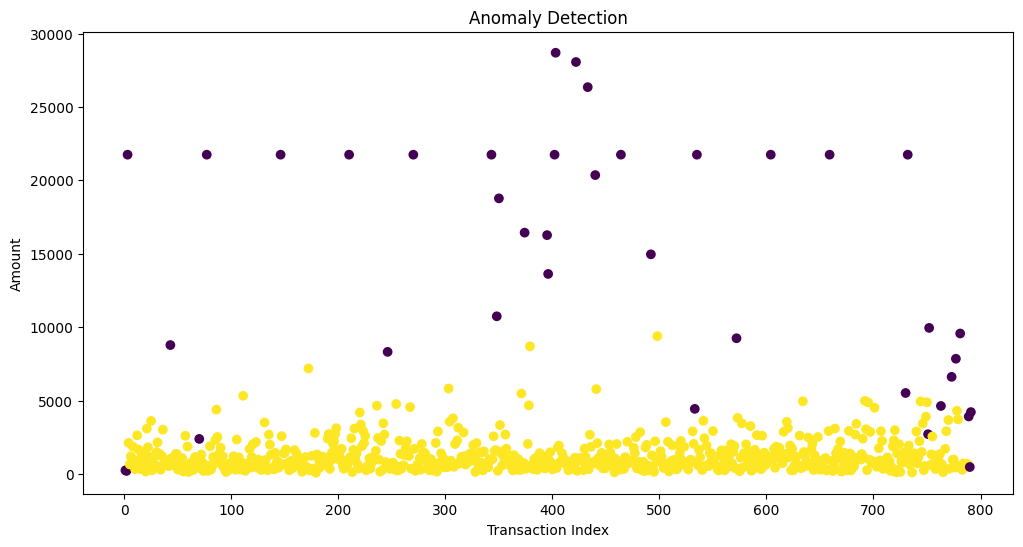

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.scatter(
    df_expenses.index,
    df_expenses["Amount"],
    c=df_expenses["Anomaly"]
)

plt.title("Anomaly Detection")
plt.xlabel("Transaction Index")
plt.ylabel("Amount")

plt.show()

**Anomaly code**

In [31]:
import joblib

joblib.dump(
    iso,
    "../models/anomaly_model.pkl"
)

['../models/anomaly_model.pkl']

In [32]:
df_budget.shape

(14, 13)

In [33]:
monthly_spending.rename(
    columns={"Amount":"Total_Spend"},
    inplace=True
)

monthly_spending

In [34]:
category_features = pd.pivot_table(
    category_summary,
    index=["Year","Month"],
    columns="Category",
    values="Amount",
    fill_value=0
)

category_features.reset_index(
    inplace=True
)

category_features.head()

Category,Year,Month,Education & Self-Dev,Entertainment & Leisure,Food & Groceries,Gifts & Social,Health & Wellness,Personal Care,Rent,Restaurants & Cafés,Savings & Investment,Shopping & Clothing,Subscriptions & Digital,Transport,Travel & Holidays,Utilities
0,2024,1,9958.629,2300.135,17561.559,4170.664,6098.120,2914.761,21750.0,4976.806,8787.0,7328.358,812.0,7709.708,3670.588,6032.0
1,2024,2,5878.155,3489.773,13395.390,6739.542,6651.614,1290.123,21750.0,3264.762,5336.0,8331.845,812.0,2906.438,3078.698,5075.0
2,2024,3,3615.952,1697.370,15283.580,4732.075,5561.069,6928.216,21750.0,2767.064,7192.0,11090.528,812.0,4002.174,4866.780,5249.0
3,2024,4,6436.057,4234.377,21929.481,11173.787,9137.001,2972.442,21750.0,1078.713,8323.0,11103.288,812.0,2726.319,5626.145,7221.0
4,2024,5,7979.466,2285.925,10165.892,10091.855,7194.929,2819.148,21750.0,6346.012,5829.0,7151.255,812.0,4487.547,11262.382,5336.0


In [35]:
df_budget

In [36]:
budget_long = pd.melt(
    df_budget,
    id_vars=["Category"],
    var_name="Month_Year",
    value_name="Budget"
)

budget_long.head()

,Category,Month_Year,Budget
0,Food & Groceries,January 2024,450
1,Transport,January 2024,180
2,Restaurants & Cafés,January 2024,150
3,Health & Wellness,January 2024,200
4,Education & Self-Dev,January 2024,200


In [37]:
month_map = {
    "January 2024":1,
    "February 2024":2,
    "March 2024":3,
    "April 2024":4,
    "May 2024":5,
    "June 2024":6,
    "July 2024":7,
    "August 2024":8,
    "September 2024":9,
    "October 2024":10,
    "November 2024":11,
    "December 2024":12
}

budget_long["Month"] = (
    budget_long["Month_Year"]
    .map(month_map)
)

In [38]:
merged_df = pd.merge(
    category_summary,
    budget_long[["Category", "Month", "Budget"]],
    on=["Category", "Month"],
    how="inner"
)

merged_df.head()

,Year,Month,Category,Amount,Budget
0,2024,1,Education & Self-Dev,9958.629,200
1,2024,1,Entertainment & Leisure,2300.135,100
2,2024,1,Food & Groceries,17561.559,450
3,2024,1,Gifts & Social,4170.664,150
4,2024,1,Health & Wellness,6098.120,200


In [39]:
merged_df["Overspent"] = (
    merged_df["Amount"] >
    merged_df["Budget"]
).astype(int)

In [40]:
merged_df["Overspent"].value_counts()

Overspent
1    167
Name: count, dtype: int64

In [41]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

merged_df["Category"] = le.fit_transform(
    merged_df["Category"]
)

In [42]:
X = merged_df[
    [
        "Category",
        "Month",
        "Budget",
        "Amount"
    ]
]

In [43]:
y = merged_df["Overspent"]

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [45]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(
    X_train,
    y_train
)

In [46]:
y_pred = rf.predict(X_test)

In [47]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 1.0


In [48]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        34

    accuracy                           1.00        34
   macro avg       1.00      1.00      1.00        34
weighted avg       1.00      1.00      1.00        34



In [49]:
joblib.dump(
    rf,
    "../models/overspend_model.pkl"
)

['../models/overspend_model.pkl']

**Model is saved here**

In [51]:
merged_df.head()

,Year,Month,Category,Amount,Budget,Overspent
0,2024,1,0,9958.629,200,1
1,2024,1,1,2300.135,100,1
2,2024,1,2,17561.559,450,1
3,2024,1,3,4170.664,150,1
4,2024,1,4,6098.120,200,1
